# =========================================================
# RAIL DEFECT SEGMENTATION & SEVERITY PIPELINE (SINGLE FILE)
# Model: U-Net with EfficientNet-B0
# Task : Binary segmentation (class-wise folders)
# Class - Rail End Batter
# =========================================================

STEP 0️⃣ – GLOBAL SETTINGS (RUN FIRST)

In [1]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.8 MB/s eta 0:00:00


In [2]:
import os
import cv2
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp


In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_DEFECT = "Rail End Batter"
EPOCHS = 20
BATCH_SIZE = 4
LR = 1e-4


✅ Verify

In [4]:
print("Device:", DEVICE)
print("Target defect:", TARGET_DEFECT)


Device: cuda
Target defect: Rail End Batter


STEP 1️⃣ – DATASET CLASS (NO AUGMENTATION YET)

STEP 2️⃣ – DISPLAY FEW SAMPLES AFTER LOADING DATASET ✅ (POINT 1)

In [5]:
import os, cv2, torch, numpy as np
from torch.utils.data import Dataset

class RailDataset(Dataset):
    def __init__(self, defect_path, transform=None, skip_empty_masks=True):
        self.defect_path = defect_path
        self.image_dir = os.path.join(defect_path, "Images")
        self.mask_dir  = os.path.join(defect_path, "masks")
        self.transform = transform

        self.images = []

        for f in sorted(os.listdir(self.image_dir)):
            if not f.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            img_path  = os.path.join(self.image_dir, f)
            name, _   = os.path.splitext(f)
            mask_path = os.path.join(self.mask_dir, name + ".png")

            if not os.path.exists(mask_path):
                continue

            if skip_empty_masks:
                mask = cv2.imread(mask_path, 0)
                if mask is None or np.sum(mask) == 0:
                    continue

            self.images.append(img_path)

        print(f"Loaded {len(self.images)} non-empty mask samples")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        img_name = os.path.basename(img_path)
        name, _ = os.path.splitext(img_name)

        mask_path = os.path.join(self.mask_dir, name + ".png")

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, 0)
        if mask is None:
            raise FileNotFoundError(f"Mask missing for {img_name}")

        mask = (mask > 0).astype("float32")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
        else:
            image = torch.from_numpy(image).permute(2,0,1).float()

        mask = torch.tensor(mask).unsqueeze(0)

        return image, mask, img_name


In [6]:
def show_samples(dataset, n=3):
    plt.figure(figsize=(8, 3*n))

    for i in range(n):
        img, mask, _ = dataset[i]   # unpack image, mask, filename

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img.permute(1,2,0).numpy() / 255.0)  # ✅ FIX
        plt.title("Image")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask.squeeze(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.show()




Loaded 167 non-empty mask samples


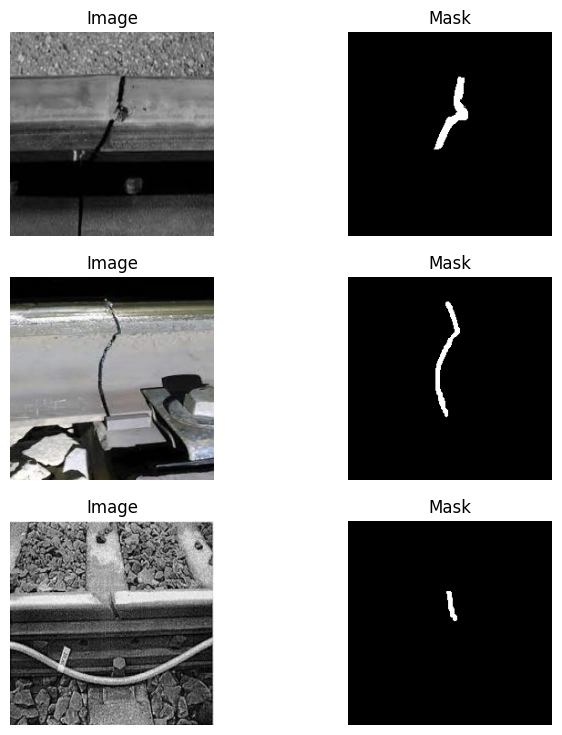

In [8]:
train_defect_path = "/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Rail End Batter"

train_ds_plain = RailDataset(train_defect_path)
show_samples(train_ds_plain)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


STEP 3️⃣ – ENVIRONMENT-WISE DATA AUGMENTATION + DISPLAY ✅ (POINT 2)

Morning

In [9]:
# -------------------------
# Sample environmental augmentations
# -------------------------
aug_rain = A.Compose([
    A.RandomRain(p=1.0)
])

aug_fog = A.Compose([
    A.RandomFog(
        fog_coef_lower=0.3,
        fog_coef_upper=0.6,
        alpha_coef=0.1,
        p=1.0
    )
])

aug_snow = A.Compose([
    A.RandomSnow(
        snow_point_lower=0.1,
        snow_point_upper=0.3,
        brightness_coeff=1.5,
        p=1.0
    )
])

# -------------------------
# Sample lighting augmentations
# -------------------------
aug_morning = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(0.1, 0.3),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_evening = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.3, -0.1),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_night = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.5, -0.3),
        contrast_limit=(0.1, 0.3),
        p=1.0
    )
])


/tmp/ipykernel_1361/830839087.py:9: UserWarning: Argument(s) 'fog_coef_lower, fog_coef_upper' are not valid for transform RandomFog
  A.RandomFog(
/tmp/ipykernel_1361/830839087.py:18: UserWarning: Argument(s) 'snow_point_lower, snow_point_upper' are not valid for transform RandomSnow
  A.RandomSnow(


In [10]:
def show_augmentations(dataset, aug_list, titles):
    img, mask, _ = dataset[0]

    # Convert tensor → numpy uint8 (Albumentations needs this)
    img = img.permute(1,2,0).numpy()
    img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)

    mask = mask.squeeze().numpy().astype(np.uint8)

    plt.figure(figsize=(18, 3))

    for i, aug in enumerate(aug_list):
        out = aug(image=img, mask=mask)

        aug_img = out["image"].astype(np.float32) / 255.0  # for display

        plt.subplot(1, len(aug_list), i+1)
        plt.imshow(aug_img)
        plt.title(titles[i])
        plt.axis("off")

    plt.show()



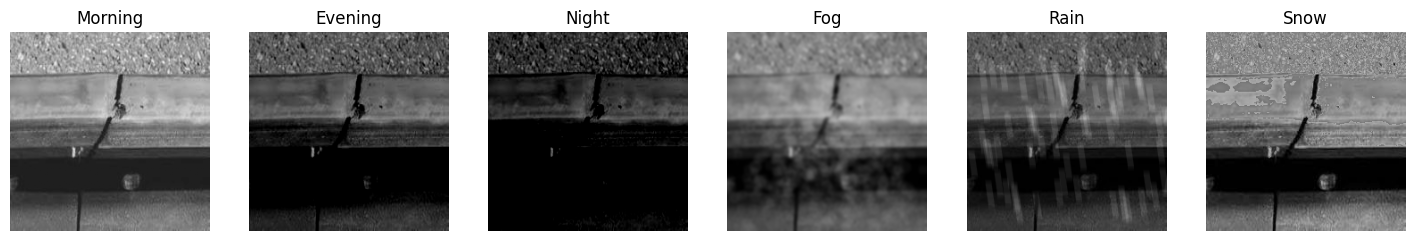

In [11]:
show_augmentations(
    train_ds_plain,
    [aug_morning, aug_evening, aug_night, aug_fog, aug_rain, aug_snow],
    ["Morning", "Evening", "Night", "Fog", "Rain", "Snow"]
)

STEP 4️⃣ – FINAL TRANSFORMS & LOADERS

In [12]:
from albumentations.pytorch import ToTensorV2

train_tfms = A.Compose([
    A.Resize(512, 512),

    A.HorizontalFlip(p=0.5),

    A.OneOf([
        aug_morning,
        aug_evening,
        aug_night,
        aug_fog,
        aug_rain
    ], p=0.7),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()   # ✅ THIS IS THE KEY FIX
])



In [13]:
val_tfms = A.Compose([
    A.Resize(512, 512),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


In [14]:
train_ds = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Rail End Batter", train_tfms)
val_ds   = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Validation Set/Rail End Batter", val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train samples:", len(train_ds))
print("Val samples:", len(val_ds))


Loaded 167 non-empty mask samples
Loaded 38 non-empty mask samples
Train samples: 167
Val samples: 38


HOW TO VERIFY AUGMENTATION IS REALLY APPLIED (VISUAL PROOF)

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def show_augmented_samples(dataset, n=3):
    plt.figure(figsize=(8, 4*n))

    for i in range(n):
        img, mask, name = dataset[i]

        # ---------- IMAGE ----------
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu()
            img = img.permute(1, 2, 0).numpy()
        elif isinstance(img, np.ndarray):
            if img.ndim == 3:
                pass
            else:
                raise ValueError("Unexpected image shape")

        # Normalize only for display
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        # ---------- MASK ----------
        if isinstance(mask, torch.Tensor):
            mask = mask.detach().cpu().squeeze().numpy()
        elif isinstance(mask, np.ndarray):
            mask = mask.squeeze()

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img)
        plt.title(f"Augmented Image\n{name}")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask, cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


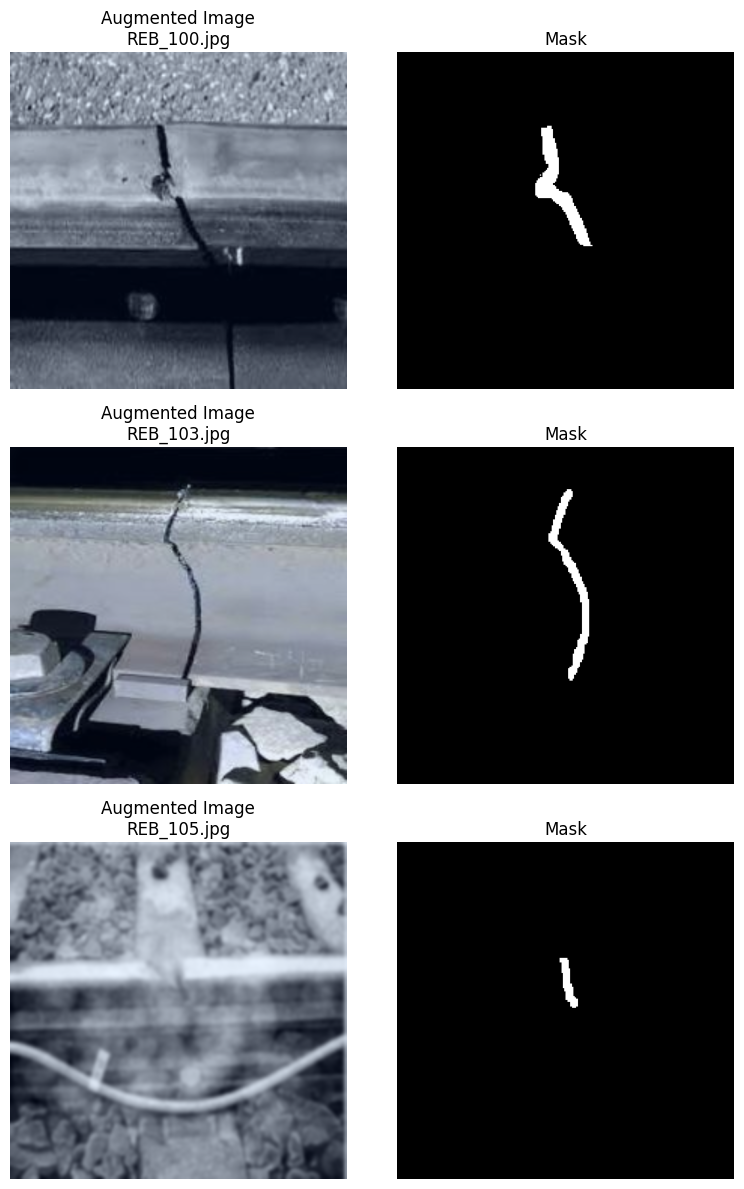

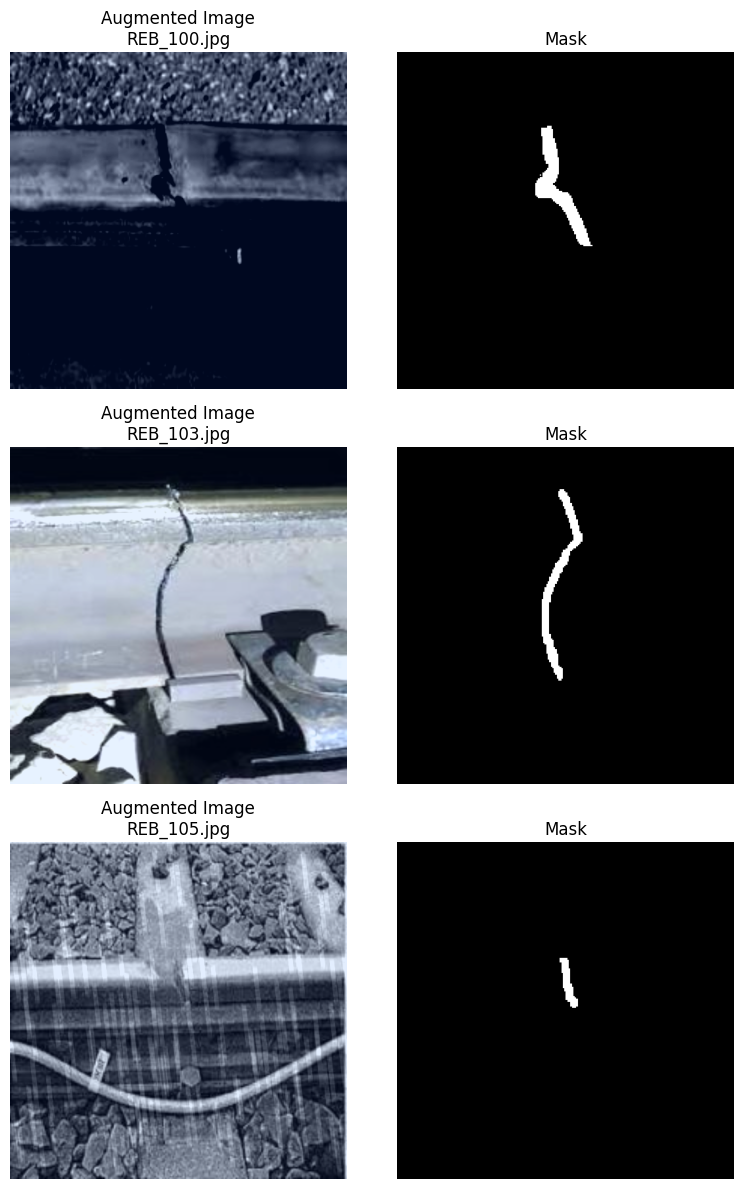

In [16]:
show_augmented_samples(train_ds)
show_augmented_samples(train_ds)


STEP 5️⃣ – MODEL, LOSS, METRICS ✅ (POINT 3)

In [17]:
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

In [18]:
from scipy.ndimage import distance_transform_edt

def boundary_loss(pred, gt):
    """
    Normalized boundary loss (stable).
    """
    gt_np = gt.detach().cpu().numpy()

    # Distance transform
    dist = distance_transform_edt(1 - gt_np)

    # Normalize distance map to [0,1]
    dist = dist / (dist.max() + 1e-8)

    dist = torch.tensor(dist, device=pred.device).float()

    pred = torch.sigmoid(pred)

    return (pred * dist).mean()




In [19]:
# =========================
# OPTION 2: FOCAL TVERSKY LOSS
# =========================

bce = nn.BCEWithLogitsLoss()

tversky = smp.losses.TverskyLoss(
    mode="binary",
    alpha=0.7,
    beta=0.3
)

def loss_fn(pred, gt):
    return (
        0.50 * bce(pred, gt) +
        0.40 * tversky(pred, gt) +
        0.10 * boundary_loss(pred, gt)
    )




In [20]:
def dice_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return (2*inter + eps) / (union + eps)


Hausdorff distance

In [21]:
from scipy.spatial.distance import directed_hausdorff
import numpy as np


In [22]:
def hausdorff_distance(pred_mask, gt_mask):
    """
    Computes symmetric Hausdorff Distance (in pixels)
    pred_mask, gt_mask: binary numpy arrays (H,W)
    """
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    # If either mask is empty, HD is undefined → return large value
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    hd1 = directed_hausdorff(pred_pts, gt_pts)[0]
    hd2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return max(hd1, hd2)


STEP 6️⃣ – TRAINING + ALL METRICS + RUNTIME ✅ (POINT 4)

6.1 METRIC FUNCTIONS (ADD ONCE)

In [23]:
def iou_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + eps) / (union + eps)

def pixel_accuracy(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    correct = (pred == gt).float().sum()
    total = torch.numel(pred)
    return correct / total

def precision_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fp = (pred * (1 - gt)).sum()
    return (tp + eps) / (tp + fp + eps)

def recall_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fn = ((1 - pred) * gt).sum()
    return (tp + eps) / (tp + fn + eps)


6.2 HISTORY DICTIONARY (FOR CURVES LATER)

In [24]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    #verbose=True
)


start_time = time.time()



In [25]:
history = {
    # Loss
    "train_loss": [],
    "val_loss": [],

    # Dice & IoU
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],

    # Accuracy / Precision / Recall
    "train_acc": [],
    "val_acc": [],
    "train_prec": [],
    "val_prec": [],
    "train_rec": [],
    "val_rec": [],

    # Hausdorff
    "train_hd": [],
    "val_hd": []
}


In [26]:
best_val_dice = 0.0
epoch_times = []
total_training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0

    train_hd = []

    for imgs, masks, _ in train_loader:   # ✅ FIXED
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


        # Hausdorff (TRAIN)
        preds_bin = (torch.sigmoid(preds) > 0.5).float()
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i, 0].cpu().numpy()
            gt_np   = masks[i, 0].cpu().numpy()
            hd = hausdorff_distance(pred_np, gt_np)
            if not np.isnan(hd):
                train_hd.append(hd)

    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)

    mean_train_hd = np.mean(train_hd) if len(train_hd) > 0 else np.nan
    history["train_hd"].append(mean_train_hd)

    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:   # ✅ FIXED
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            # Hausdorff (VAL)
            preds_bin = (torch.sigmoid(preds) > 0.5).float()
            for i in range(preds_bin.size(0)):
                pred_np = preds_bin[i, 0].cpu().numpy()
                gt_np   = masks[i, 0].cpu().numpy()
                hd = hausdorff_distance(pred_np, gt_np)
                if not np.isnan(hd):
                    val_hd.append(hd)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_val_hd = np.mean(val_hd) if len(val_hd) > 0 else np.nan
    history["val_hd"].append(mean_val_hd)

    scheduler.step(vd)

    # ================= SAVE HISTORY =================
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_dice"].append(td)
    history["val_dice"].append(vd)
    history["train_iou"].append(ti)
    history["val_iou"].append(vi)
    history["train_acc"].append(tacc)
    history["val_acc"].append(vacc)
    history["train_prec"].append(tprec)
    history["val_prec"].append(vprec)
    history["train_rec"].append(trec)
    history["val_rec"].append(vrec)





    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_dice": best_val_dice,
            "architecture": "Unet++",
            "encoder": "efficientnet-b0",
            "defect": "Hogging of Rails",
            "image_size": 512
        }
        torch.save(checkpoint, "best_unetpp_effb0_Hogging.pth")

    # ================= RUNTIME =================
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)

    # ================= PRINT METRICS (COMPLETE) =================
    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )


# ================= TOTAL TIME =================
total_training_time = time.time() - total_training_start
print("Total training time:", total_training_time)
print("Avg epoch time:", sum(epoch_times) / len(epoch_times))




/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 106.5s
  Train → Loss=0.8593, Dice=0.0672, IoU=0.0353, Acc=0.2582, Prec=0.0358, Rec=0.7539, HD=367.81px
  Val   → Loss=0.8188, Dice=0.0540, IoU=0.0282, Acc=0.2621, Prec=0.0285, Rec=0.7869, HD=382.75px

Epoch [2/20] | Time 66.1s
  Train → Loss=0.7546, Dice=0.0885, IoU=0.0471, Acc=0.5219, Prec=0.0487, Rec=0.6920, HD=367.61px
  Val   → Loss=0.7068, Dice=0.1373, IoU=0.0750, Acc=0.7250, Prec=0.0763, Rec=0.9009, HD=382.45px

Epoch [3/20] | Time 40.1s
  Train → Loss=0.6555, Dice=0.2204, IoU=0.1288, Acc=0.8358, Prec=0.1495, Rec=0.6994, HD=366.88px
  Val   → Loss=0.6176, Dice=0.3575, IoU=0.2226, Acc=0.9372, Prec=0.2437, Rec=0.7695, HD=381.45px

Epoch [4/20] | Time 39.3s
  Train → Loss=0.5899, Dice=0.3821, IoU=0.2464, Acc=0.9315, Prec=0.3005, Rec=0.7082, HD=364.73px
  Val   → Loss=0.5592, Dice=0.5433, IoU=0.3783, Acc=0.9700, Prec=0.4406, Rec=0.7683, HD=379.51px

Epoch [5/20] | Time 37.9s
  Train → Loss=0.5455, Dice=0.4961, IoU=0.3406, Acc=0.9545, Prec=0.4219, Rec=0.7346, HD=3

ADD THIS FUNCTION (RUN AFTER TRAINING)

In [27]:
import numpy as np
import torch

def find_best_iou_threshold(model, val_loader):
    model.eval()
    thresholds = np.arange(0.4, 0.8, 0.05)

    best_iou = 0.0
    best_t = 0.5

    with torch.no_grad():
        for t in thresholds:
            iou_sum = 0.0

            for imgs, masks, _ in val_loader:   # ✅ FIX HERE
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                probs = torch.sigmoid(model(imgs))
                preds = (probs > t).float()
                iou_sum += iou_score(preds, masks).item()

            mean_iou = iou_sum / len(val_loader)

            print(f"Threshold {t:.2f} → IoU {mean_iou:.4f}")

            if mean_iou > best_iou:
                best_iou = mean_iou
                best_t = t

    print(f"\n✔ Best threshold = {best_t:.2f}, IoU = {best_iou:.4f}")
    return best_t, best_iou


In [28]:
best_t, best_iou = find_best_iou_threshold(model, val_loader)



/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Threshold 0.40 → IoU 0.5586
Threshold 0.45 → IoU 0.5584
Threshold 0.50 → IoU 0.5576
Threshold 0.55 → IoU 0.5565
Threshold 0.60 → IoU 0.5544
Threshold 0.65 → IoU 0.5522
Threshold 0.70 → IoU 0.5480
Threshold 0.75 → IoU 0.5414

✔ Best threshold = 0.40, IoU = 0.5586


STEP 7️⃣ – ACCURACY & LOSS CURVES ✅ (POINT 5)

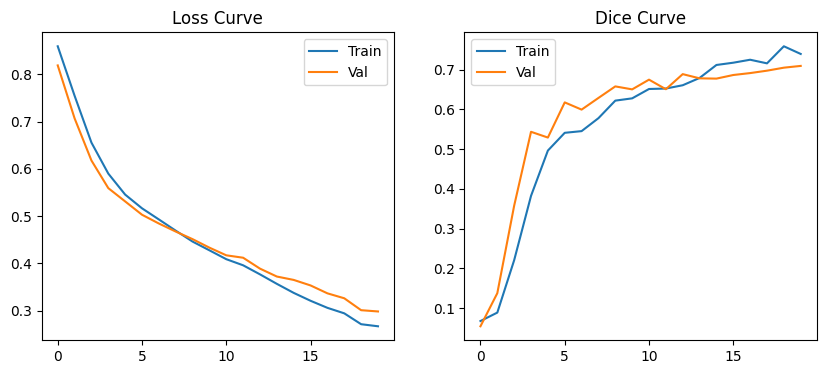

In [29]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_dice"], label="Train")
plt.plot(history["val_dice"], label="Val")
plt.title("Dice Curve")
plt.legend()
plt.show()




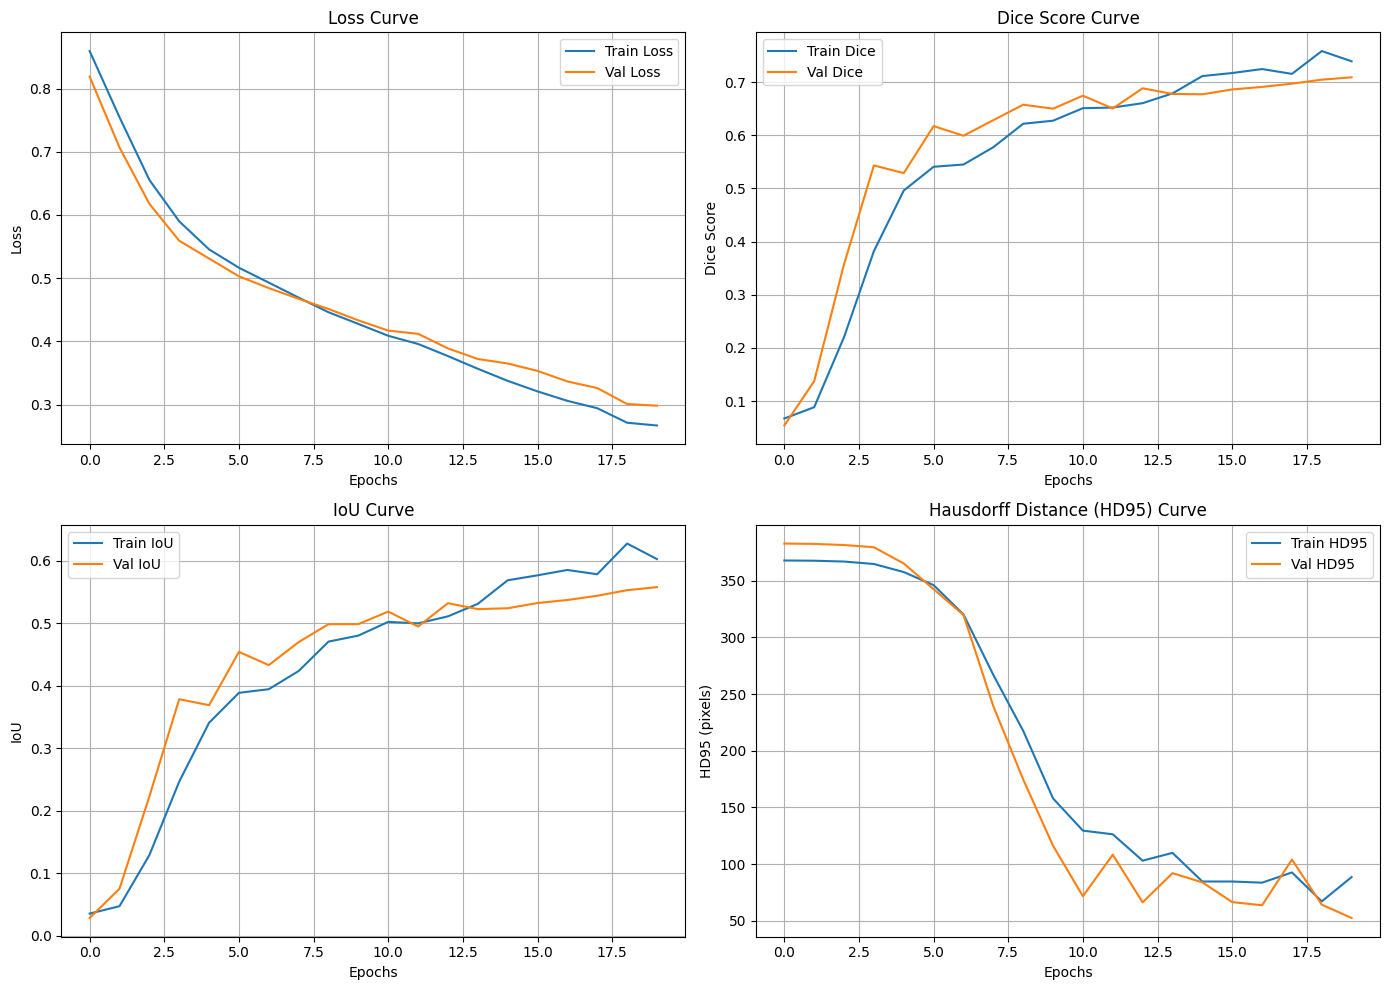

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# ---------------- Loss Curve ----------------
plt.subplot(2, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------------- Dice Curve ----------------
plt.subplot(2, 2, 2)
plt.plot(history["train_dice"], label="Train Dice")
plt.plot(history["val_dice"], label="Val Dice")
plt.title("Dice Score Curve")
plt.xlabel("Epochs")
plt.ylabel("Dice Score")
plt.legend()
plt.grid(True)

# ---------------- IoU Curve ----------------
plt.subplot(2, 2, 3)
plt.plot(history["train_iou"], label="Train IoU")
plt.plot(history["val_iou"], label="Val IoU")
plt.title("IoU Curve")
plt.xlabel("Epochs")
plt.ylabel("IoU")
plt.legend()
plt.grid(True)

# ---------------- Hausdorff Distance Curve ----------------
plt.subplot(2, 2, 4)
plt.plot(history["train_hd"], label="Train HD95")
plt.plot(history["val_hd"], label="Val HD95")
plt.title("Hausdorff Distance (HD95) Curve")
plt.xlabel("Epochs")
plt.ylabel("HD95 (pixels)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


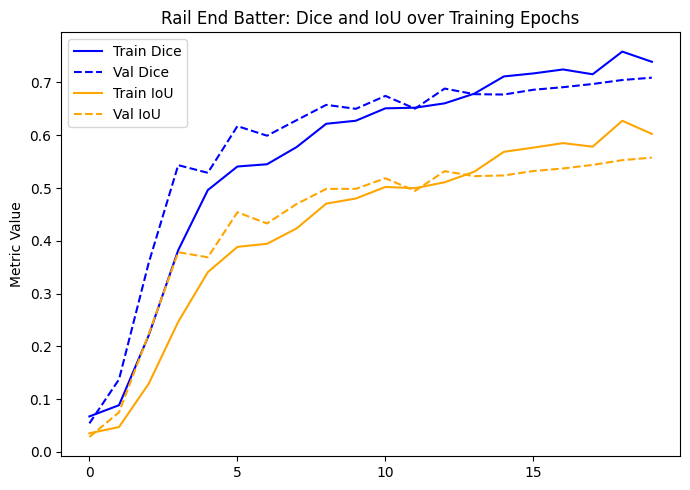

In [31]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Rail End Batter: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()



Apply CRF post-processing once

In [32]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.spatial.distance import directed_hausdorff



In [33]:
def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


In [34]:
best_val_dice = 0.0
epoch_times = []
total_start = time.time()

for epoch in range(EPOCHS):
    start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0


    for imgs, masks , _ in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)


    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd95 = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            probs = torch.sigmoid(preds)

            for i in range(imgs.size(0)):
                 pred_bin = (probs[i,0] > 0.5).cpu().numpy()
                 gt_np    = masks[i,0].cpu().numpy()

                 hd95 = hausdorff_distance_95(pred_bin, gt_np)
                 if not np.isnan(hd95):
                     val_hd95.append(hd95)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_hd95 = np.mean(val_hd95)

    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "best_val_dice": best_val_dice
        }, "best_unetpp_effb0_REB.pth")

    epoch_time = time.time() - start
    epoch_times.append(epoch_time)

    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )

print("\nTotal training time:", time.time() - total_start)
print("Avg epoch time:", sum(epoch_times)/len(epoch_times))


/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 29.5s
  Train → Loss=0.2487, Dice=0.7686, IoU=0.6377, Acc=0.9840, Prec=0.7383, Rec=0.8516, HD=88.51px
  Val   → Loss=0.2919, Dice=0.6981, IoU=0.5446, Acc=0.9804, Prec=0.5948, Rec=0.8728, HD=52.36px

Epoch [2/20] | Time 29.6s
  Train → Loss=0.2277, Dice=0.7783, IoU=0.6491, Acc=0.9854, Prec=0.7472, Rec=0.8566, HD=88.51px
  Val   → Loss=0.2805, Dice=0.6858, IoU=0.5327, Acc=0.9832, Prec=0.7113, Rec=0.6916, HD=52.36px

Epoch [3/20] | Time 28.6s
  Train → Loss=0.2256, Dice=0.7633, IoU=0.6288, Acc=0.9850, Prec=0.7361, Rec=0.8337, HD=88.51px
  Val   → Loss=0.2550, Dice=0.7299, IoU=0.5807, Acc=0.9849, Prec=0.7385, Rec=0.7458, HD=52.36px

Epoch [4/20] | Time 28.0s
  Train → Loss=0.2065, Dice=0.7814, IoU=0.6511, Acc=0.9863, Prec=0.7676, Rec=0.8263, HD=88.51px
  Val   → Loss=0.2448, Dice=0.7192, IoU=0.5672, Acc=0.9830, Prec=0.6548, Rec=0.8139, HD=52.36px

Epoch [5/20] | Time 27.8s
  Train → Loss=0.1939, Dice=0.7879, IoU=0.6588, Acc=0.9860, Prec=0.7702, Rec=0.8309, HD=88.51px
  

Save Model

In [36]:
import torch

# --------------------------------------------------
# SAVE TRAINED UNet++ EfficientNet-B0 MODEL
# --------------------------------------------------

SAVE_PATH = "/content/unetpp_efficientnetb0_rail_end_batter.pth"

# Save only the model weights (best practice)
torch.save(model.state_dict(), SAVE_PATH)

print("✅ Trained model saved successfully")
print("📁 Model path:", SAVE_PATH)


✅ Trained model saved successfully
📁 Model path: /content/unetpp_efficientnetb0_rail_end_batter.pth


Draw Graph

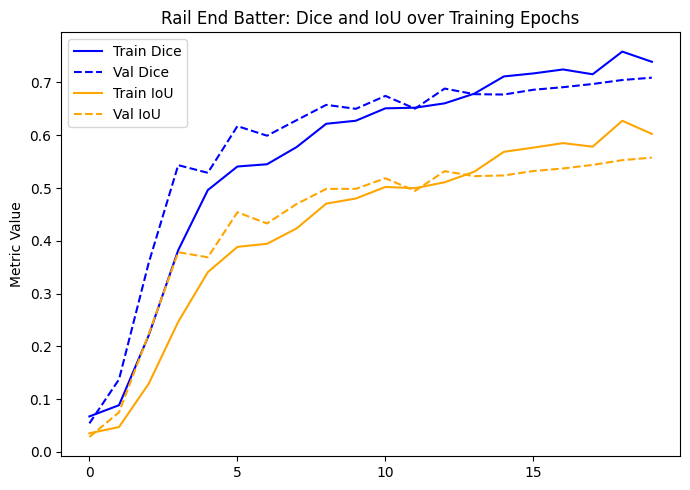

In [37]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Rail End Batter: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()


Run on Test Data

STEP 1 — LOAD BEST TRAINED MODEL

In [38]:
checkpoint = torch.load(
    "best_unetpp_effb0_REB.pth",
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("✔ Best model loaded")
print("Best Val Dice:", checkpoint["best_val_dice"])


✔ Best model loaded
Best Val Dice: 0.7511009335517883


STEP 2 — TEST DATASET & LOADER

In [39]:
TEST_PATH = (
    "/content/drive/MyDrive/Severity Calculation Data Set/With Split/Test Set/Rail End Batter"
)

test_ds = RailDataset(TEST_PATH, transform=val_tfms)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Test samples:", len(test_ds))


Loaded 36 non-empty mask samples
Test samples: 36


STEP 3 — HD95 FUNCTION (ROBUST & FINAL)

In [40]:
from scipy.spatial.distance import directed_hausdorff

def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


STEP 4 — RUN MODEL ON TEST DATA (CORE)

In [41]:
test_dice = test_iou = test_acc = test_prec = test_rec = 0.0
test_hd95 = []

with torch.no_grad():
    for imgs, masks, img_names in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        probs = torch.sigmoid(preds)
        preds_bin = (probs > 0.5).float()

        test_dice += dice_score(preds, masks).item()
        test_iou  += iou_score(preds, masks).item()
        test_acc  += pixel_accuracy(preds, masks).item()
        test_prec += precision_score(preds, masks).item()
        test_rec  += recall_score(preds, masks).item()

        # HD95 (per image)
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i,0].cpu().numpy()
            gt_np   = masks[i,0].cpu().numpy()

            hd95 = hausdorff_distance_95(pred_np, gt_np)
            if not np.isnan(hd95):
                test_hd95.append(hd95)

# Averages
test_dice /= len(test_loader)
test_iou  /= len(test_loader)
test_acc  /= len(test_loader)
test_prec /= len(test_loader)
test_rec  /= len(test_loader)
mean_test_hd95 = np.mean(test_hd95)


/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


STEP 5 — PRINT FINAL TEST RESULTS (PAPER-READY)

In [42]:
print("\n========== FINAL TEST RESULTS ==========")
print(f"Dice Score       : {test_dice:.4f}")
print(f"IoU              : {test_iou:.4f}")
print(f"Accuracy         : {test_acc:.4f}")
print(f"Precision        : {test_prec:.4f}")
print(f"Recall           : {test_rec:.4f}")
print(f"HD95 (pixels)    : {mean_test_hd95:.2f}")



========== FINAL TEST RESULTS ==========
Dice Score       : 0.7401
IoU              : 0.6091
Accuracy         : 0.9900
Precision        : 0.7586
Recall           : 0.7315
HD95 (pixels)    : 37.37


STEP 1 — SEVERITY CALCULATION FUNCTION (FINAL)

In [43]:
# ============================================================
# RAIL END BATTER SEVERITY CALCULATION (VISION-BASED)
# As per MM Agarwal / Indian Railways definition
# ============================================================

import numpy as np
import cv2

# ------------------------------------------------------------
# STEP 1: OFFICIAL SEVERITY THRESHOLDS (DO NOT CHANGE)
# ------------------------------------------------------------
AVERAGE_MAX_MM = 2.0    # ≤ 2 mm  → Average
SEVERE_MAX_MM  = 3.0    # 2–3 mm → Severe
# > 3 mm        → Critical

# ------------------------------------------------------------
# STEP 2: PIXEL → MILLIMETER CALIBRATION
# ------------------------------------------------------------
# Adjust this based on your camera setup
# Example: 1 pixel = 0.25 mm
PIXEL_TO_MM = 0.25


# ------------------------------------------------------------
# STEP 3: ESTIMATE RAIL END BATTER DEPTH (mm)
# ------------------------------------------------------------
def estimate_batter_depth_mm(mask, pixel_to_mm=PIXEL_TO_MM):
    """
    Estimates vertical batter depth from predicted mask

    Parameters:
        mask : numpy array [H, W] or [1, H, W]
        pixel_to_mm : conversion factor

    Returns:
        depth_mm : float
    """

    # Ensure 2D mask
    if mask.ndim == 3:
        mask = mask[0]

    # Get defect pixel coordinates
    ys, xs = np.where(mask > 0)

    # If no defect detected
    if len(ys) == 0:
        return 0.0

    # Vertical extent (pixel proxy for batter depth)
    depth_pixels = ys.max() - ys.min()

    # Convert to millimeters
    depth_mm = depth_pixels * pixel_to_mm

    return depth_mm


# ------------------------------------------------------------
# STEP 4: CLASSIFY SEVERITY (MM AGARWAL RULE)
# ------------------------------------------------------------
def classify_rail_end_batter_severity(depth_mm):
    """
    Classifies Rail End Batter severity
    """

    if depth_mm <= AVERAGE_MAX_MM:
        return "Average"
    elif depth_mm <= SEVERE_MAX_MM:
        return "Severe"
    else:
        return "Critical"


# ------------------------------------------------------------
# STEP 5: END-TO-END SEVERITY FUNCTION
# ------------------------------------------------------------
def rail_end_batter_severity(pred_mask):
    """
    Complete severity calculation pipeline

    Parameters:
        pred_mask : binary predicted mask [H,W] or [1,H,W]

    Returns:
        dict with depth and severity
    """

    depth_mm = estimate_batter_depth_mm(pred_mask)
    severity = classify_rail_end_batter_severity(depth_mm)

    return {
        "batter_depth_mm": round(depth_mm, 2),
        "severity": severity
    }


# ------------------------------------------------------------
# STEP 6: EXAMPLE USAGE (TEST / VALIDATION)
# ------------------------------------------------------------
"""
Assume:
pred_mask → model output after thresholding
Shape     → [1, H, W] or [H, W]
Binary    → 0 or 1
"""

# Example:
# result = rail_end_batter_severity(pred_mask)
# print("===== RAIL END BATTER SEVERITY REPORT =====")
# print("Batter Depth (mm):", result["batter_depth_mm"])
# print("Severity Level   :", result["severity"])


'\nAssume:\npred_mask → model output after thresholding\nShape     → [1, H, W] or [H, W]\nBinary    → 0 or 1\n'

Severity Visualization and Recommended Action

In [44]:
# ============================================================
# RAIL END BATTER – VISUALIZATION + ACTION RECOMMENDATION
# ============================================================

import numpy as np
import cv2
import matplotlib.pyplot as plt

# -------------------------------
# OFFICIAL THRESHOLDS (MM Agarwal)
# -------------------------------
AVERAGE_MAX_MM = 2.0
SEVERE_MAX_MM  = 3.0

PIXEL_TO_MM = 0.25   # adjust if calibration improves

# -------------------------------
# DEPTH ESTIMATION
# -------------------------------
def estimate_batter_depth_mm(mask, pixel_to_mm=PIXEL_TO_MM):
    if mask.ndim == 3:
        mask = mask[0]

    ys, xs = np.where(mask > 0)
    if len(ys) == 0:
        return 0.0

    depth_pixels = ys.max() - ys.min()
    return depth_pixels * pixel_to_mm


# -------------------------------
# SEVERITY CLASSIFICATION
# -------------------------------
def classify_severity(depth_mm):
    if depth_mm <= AVERAGE_MAX_MM:
        return "Average"
    elif depth_mm <= SEVERE_MAX_MM:
        return "Severe"
    else:
        return "Critical"


# -------------------------------
# ACTION RECOMMENDATION
# -------------------------------
def recommend_action(severity):
    if severity == "Average":
        return "Monitor & Rail End Grinding"
    elif severity == "Severe":
        return "Weld Repair + Grinding"
    else:
        return "Rail Cropping / Replacement"


# -------------------------------
# MAIN PIPELINE
# -------------------------------
def rail_end_batter_analysis(image, gt_mask, pred_mask):
    """
    image    : RGB image [H,W,3]
    gt_mask  : ground truth [H,W]
    pred_mask: predicted mask [H,W] or [1,H,W]
    """

    if pred_mask.ndim == 3:
        pred_mask = pred_mask[0]

    depth_mm = estimate_batter_depth_mm(pred_mask)
    severity = classify_severity(depth_mm)
    action   = recommend_action(severity)

    return depth_mm, severity, action


# -------------------------------
# VISUALIZATION FUNCTION
# -------------------------------
def visualize_result(image, gt_mask, pred_mask, depth_mm, severity, action):
    overlay = image.copy()

    # Red overlay for predicted batter
    overlay[pred_mask > 0] = [255, 0, 0]

    blended = cv2.addWeighted(image, 0.7, overlay, 0.3, 0)

    title_text = (
        f"Severity: {severity} | Depth: {depth_mm:.2f} mm\n"
        f"Action: {action}"
    )

    plt.figure(figsize=(15,4))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(blended)
    plt.title(title_text)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================
# EXAMPLE USAGE (INSIDE TEST LOOP)
# ============================================================
"""
Assume:
img        → RGB image [H,W,3]
gt_mask    → GT mask [H,W]
pred_mask  → thresholded model output [H,W] or [1,H,W]
"""

# depth_mm, severity, action = rail_end_batter_analysis(
#     img, gt_mask, pred_mask
# )
# visualize_result(img, gt_mask, pred_mask, depth_mm, severity, action)


'\nAssume:\nimg        → RGB image [H,W,3]\ngt_mask    → GT mask [H,W]\npred_mask  → thresholded model output [H,W] or [1,H,W]\n'

Imports (top of file / first cell)

In [45]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch


STEP 2 — Helper function (FIRST)

In [46]:
def denormalize_image(img, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)):
    img = img.copy()
    for i in range(3):
        img[:,:,i] = img[:,:,i] * std[i] + mean[i]
    img = np.clip(img, 0, 1)
    img = (img * 255).astype(np.uint8)
    return img


STEP 3 — Visualization function (SECOND)

In [47]:
import matplotlib.pyplot as plt
import torch
import numpy as np

def visualize_rail_end_batter_5_samples(
    model,
    dataloader,
    device,
    threshold=0.35
):
    model.eval()

    images = []
    gt_masks_list = []
    pred_masks_list = []
    infos = []
    image_names = []

    # -------- Collect exactly 5 samples --------
    with torch.no_grad():
        for imgs, gt_masks, filenames in dataloader:
            imgs = imgs.to(device)
            preds = (torch.sigmoid(model(imgs)) > threshold).float()

            for i in range(imgs.size(0)):
                img = imgs[i].cpu().permute(1, 2, 0).numpy()
                img = denormalize_image(img)

                gt_mask = gt_masks[i][0].cpu().numpy()
                pred_mask = preds[i][0].cpu().numpy()

                depth_mm, severity, action = rail_end_batter_analysis(
                    img, gt_mask, pred_mask
                )

                images.append(img)
                gt_masks_list.append(gt_mask)
                pred_masks_list.append(pred_mask)
                infos.append((depth_mm, severity, action))
                image_names.append(filenames[i])

                if len(images) == 5:
                    break
            if len(images) == 5:
                break

    # -------- Plot (5 rows × 3 columns) --------
    plt.figure(figsize=(18, 20))

    for i in range(5):
        # Original
        plt.subplot(5, 3, 3*i + 1)
        plt.imshow(images[i])
        plt.title("Original Image")
        plt.axis("off")

        # GT Mask
        plt.subplot(5, 3, 3*i + 2)
        plt.imshow(gt_masks_list[i], cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # Predicted Mask ONLY
        depth_mm, severity, action = infos[i]
        plt.subplot(5, 3, 3*i + 3)
        plt.imshow(pred_masks_list[i], cmap="gray")
        plt.title(
            f"Predicted Mask\n"
            f"Severity: {severity} | Depth: {depth_mm:.2f} mm\n"
            f"Action: {action}",
            color="red"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    # -------- Print image names separately --------
    print("\n===== IMAGE NAMES (in display order) =====")
    for idx, name in enumerate(image_names, 1):
        print(f"{idx}. {name}")


/tmp/ipykernel_1361/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


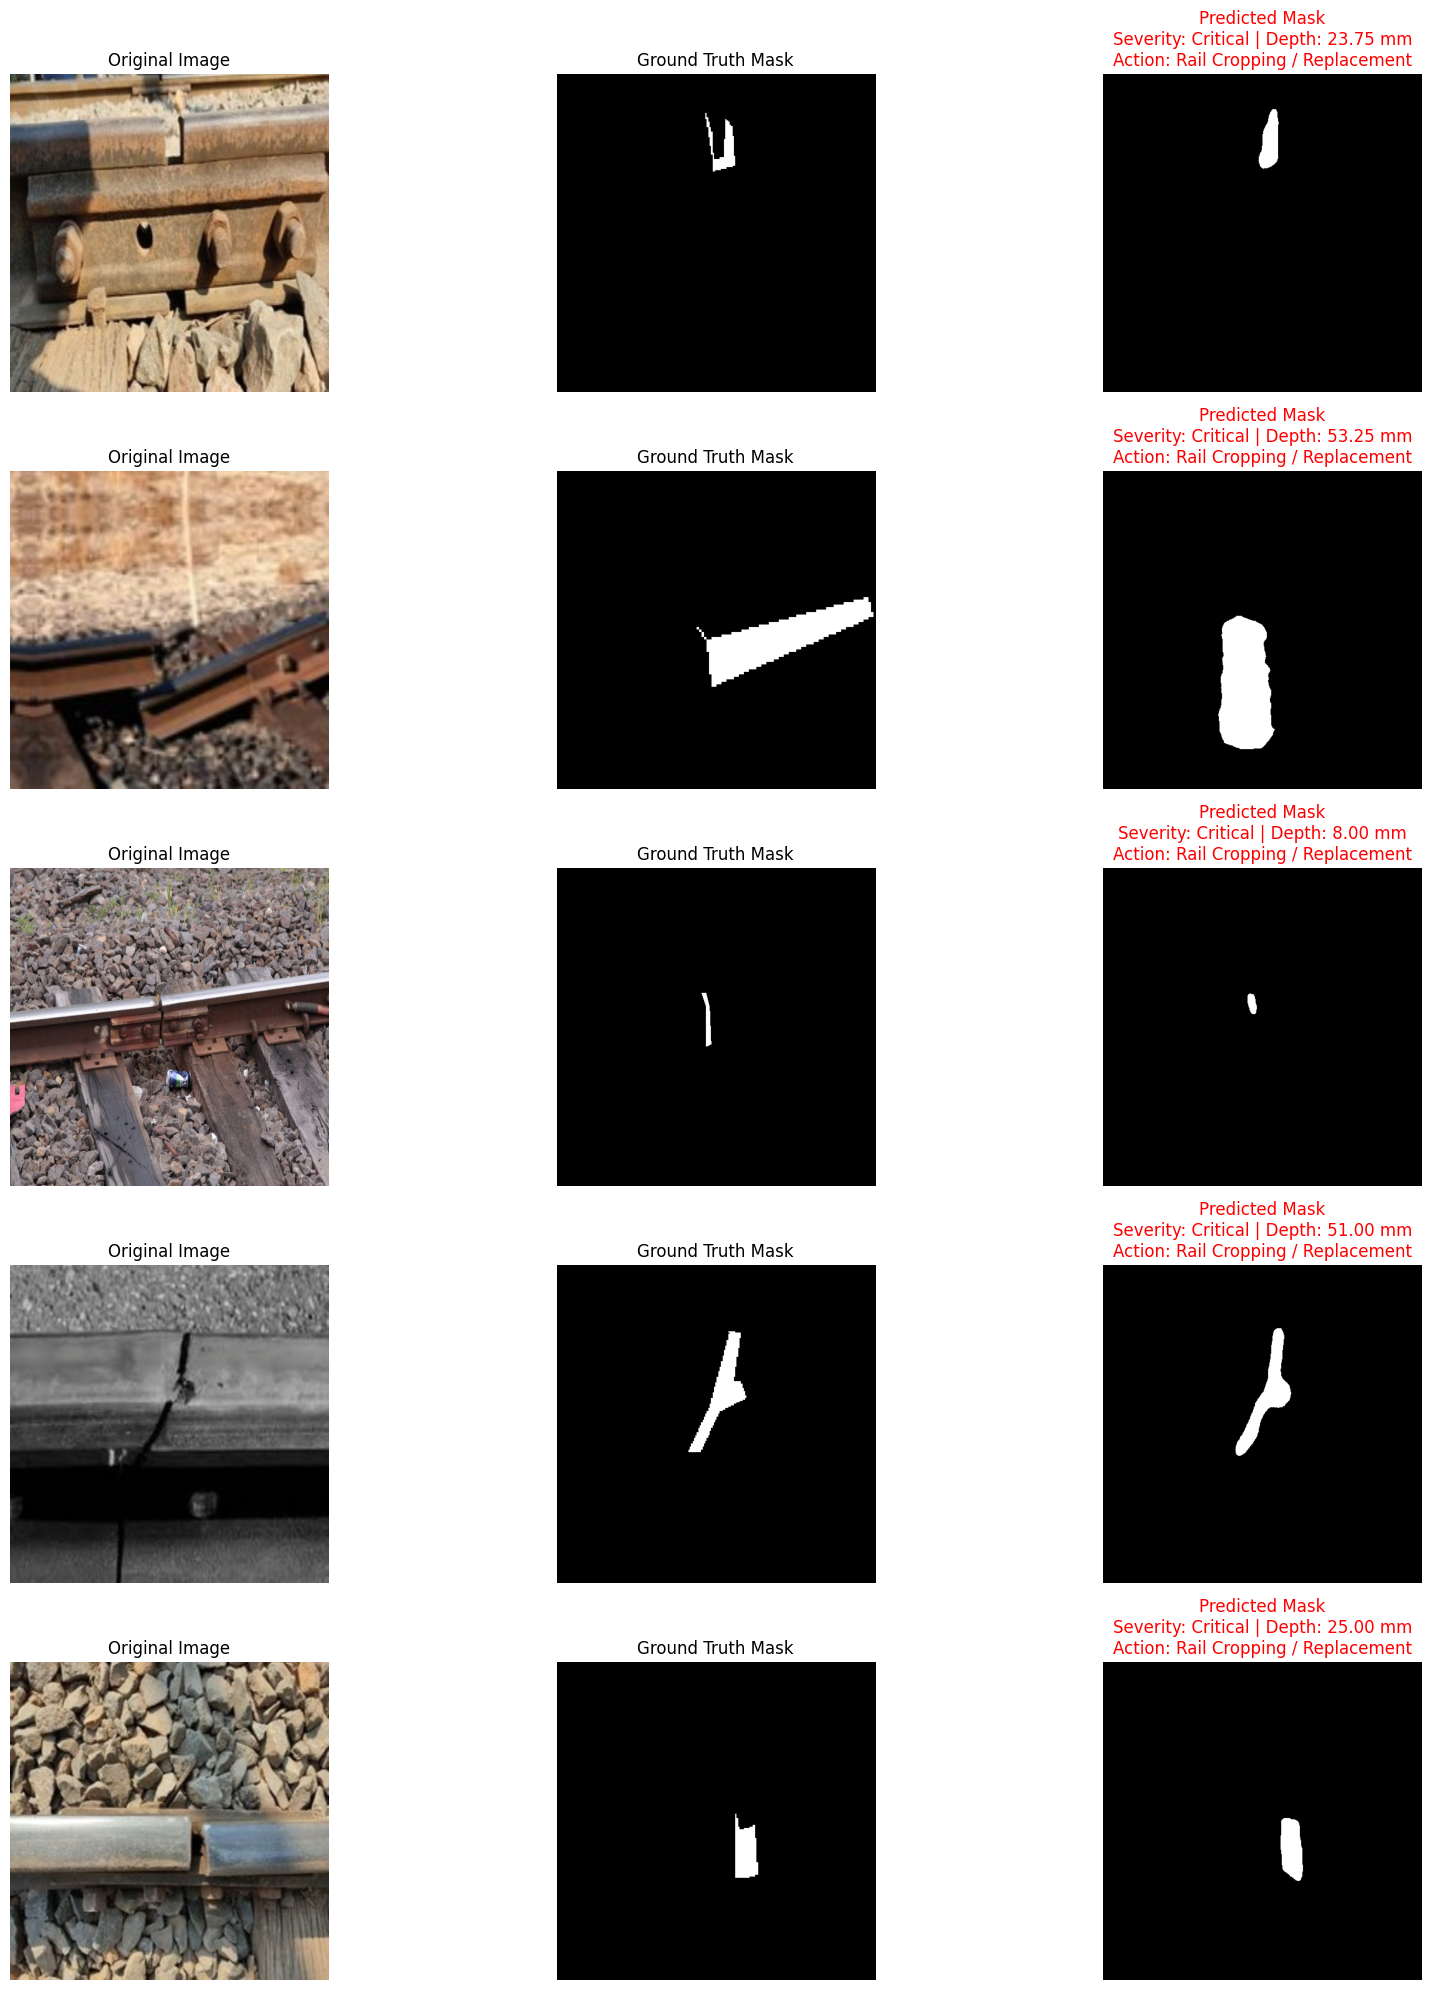


===== IMAGE NAMES (in display order) =====
1. REB_214.jpg
2. REB_215.jpg
3. REB_216.jpg
4. REB_217.jpg
5. REB_218.jpg


In [48]:
visualize_rail_end_batter_5_samples(
    model=model,
    dataloader=test_loader,
    device=DEVICE
)


STEP 1: EXTRACT FINAL / BEST VALUES AUTOMATICALLY

In [49]:
best_epoch = int(np.argmax(history["val_dice"]))

In [50]:
train_metrics = {
    "Dice": history["train_dice"][best_epoch],
    "IoU": history["train_iou"][best_epoch],
    "Accuracy": history["train_acc"][best_epoch] if "train_acc" in history else None,
    "Precision": history["train_prec"][best_epoch] if "train_prec" in history else None,
    "Recall": history["train_rec"][best_epoch] if "train_rec" in history else None,
    "HD95": history["train_hd"][best_epoch]
}
val_metrics = {
    "Dice": history["val_dice"][best_epoch],
    "IoU": history["val_iou"][best_epoch],
    "Accuracy": history["val_acc"][best_epoch],
    "Precision": history["val_prec"][best_epoch],
    "Recall": history["val_rec"][best_epoch],
    "HD95": history["val_hd"][best_epoch]
}
test_metrics = {
    "Dice": test_dice,
    "IoU": test_iou,
    "Accuracy": test_acc,
    "Precision": test_prec,
    "Recall": test_rec,
    "HD95": test_hd95
}


In [53]:
# ---------------- Fetch metrics automatically ----------------

train_metrics = {
    "Dice": history["train_dice"][-1],
    "IoU": history["train_iou"][-1],
    "Accuracy": history["val_acc"][-1] if "val_acc" in history else None,
    "Precision": history["val_prec"][-1] if "val_prec" in history else None,
    "Recall": history["val_rec"][-1] if "val_rec" in history else None,
    "HD95": history["train_hd"][-1]
}

val_metrics = {
    "Dice": history["val_dice"][-1],
    "IoU": history["val_iou"][-1],
    "Accuracy": history["val_acc"][-1],
    "Precision": history["val_prec"][-1],
    "Recall": history["val_rec"][-1],
    "HD95": history["val_hd"][-1]
}

test_metrics = {
    "Dice": test_dice,
    "IoU": test_iou,
    "Accuracy": test_acc,
    "Precision": test_prec,
    "Recall": test_rec,
    "HD95": test_hd95
}


STEP 2: BUILD RESULTS TABLE AUTOMATICALLY (NO MANUAL VALUES)

In [54]:
import numpy as np
import pandas as pd

test_hd95_mean = float(np.mean(test_metrics["HD95"]))

results_table = pd.DataFrame({
    "Dataset Split": ["Training", "Validation", "Test"],
    "Dice Score": [
        round(train_metrics["Dice"], 4),
        round(val_metrics["Dice"], 4),
        round(test_metrics["Dice"], 4)
    ],
    "IoU": [
        round(train_metrics["IoU"], 4),
        round(val_metrics["IoU"], 4),
        round(test_metrics["IoU"], 4)
    ],
    "Accuracy": [
        round(train_metrics["Accuracy"], 4),
        round(val_metrics["Accuracy"], 4),
        round(test_metrics["Accuracy"], 4)
    ],
    "Precision": [
        round(train_metrics["Precision"], 4),
        round(val_metrics["Precision"], 4),
        round(test_metrics["Precision"], 4)
    ],
    "Recall": [
        round(train_metrics["Recall"], 4),
        round(val_metrics["Recall"], 4),
        round(test_metrics["Recall"], 4)
    ],
    "HD95 (pixels)": [
        round(train_metrics["HD95"], 2),
        round(val_metrics["HD95"], 2),
        round(test_hd95_mean, 2)
    ]
})

results_table



,Dataset Split,Dice Score,IoU,Accuracy,Precision,Recall,HD95 (pixels)
0,Training,0.7391,0.6025,0.983,0.6771,0.7722,88.51
1,Validation,0.7090,0.5576,0.983,0.6771,0.7722,52.36
2,Test,0.7401,0.6091,0.990,0.7586,0.7315,37.37
